# Indian Stock Market Analysis and Return Prediction (2000–2020)
### B.E. Machine Learning Mini Project | Google Colab

**Objective:** Analyze historical Indian stock prices, study market ups and downs, engineer time-series features, and predict the next trading day's return.

**Models:** Persistence/zero-return baseline, Linear Regression, Random Forest Regressor.  
**Evaluation:** MAE, RMSE, directional accuracy, and chronological train/test split.

> Important: this is an educational experiment, not investment advice. Daily stock returns are noisy, and a good-looking historical fit does not guarantee future performance.

## 1. Install / import libraries
Run this cell first. Most libraries are preinstalled in Google Colab.

In [ ]:
import os, re, zipfile, warnings, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload ZIP file(s) and extract Excel/CSV files

Upload the dataset ZIP file(s) from your computer. This cell searches nested folders such as `archive/data/` and also extracts ZIP files contained inside uploaded ZIPs.

In [ ]:
ROOT = Path("/content/stock_project_data")
if ROOT.exists():
    shutil.rmtree(ROOT)
ROOT.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()  # Select one or more .zip files
zip_paths = []

for filename, content in uploaded.items():
    saved_path = ROOT / Path(filename).name
    saved_path.write_bytes(content)
    if saved_path.suffix.lower() == ".zip":
        zip_paths.append(saved_path)
    elif saved_path.suffix.lower() in [".xlsx", ".xls", ".csv"]:
        # Directly uploaded data files are also supported.
        pass

for zpath in zip_paths:
    with zipfile.ZipFile(zpath, "r") as zf:
        zf.extractall(ROOT / (zpath.stem + "_extracted"))

# Extract any nested ZIP files, up to several levels.
for _ in range(5):
    nested_zips = [p for p in ROOT.rglob("*.zip") if not p.name.startswith("._")]
    if not nested_zips:
        break
    extracted_any = False
    for zpath in nested_zips:
        target = zpath.parent / (zpath.stem + "_extracted")
        if target.exists():
            continue
        try:
            with zipfile.ZipFile(zpath, "r") as zf:
                zf.extractall(target)
            extracted_any = True
        except zipfile.BadZipFile:
            print("Skipping invalid ZIP:", zpath)
    if not extracted_any:
        break

data_files = [
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in [".xlsx", ".xls", ".csv"]
    and not p.name.startswith("~$")
]
print(f"Found {len(data_files)} Excel/CSV files.")
for p in data_files[:30]:
    print(p.relative_to(ROOT))
if len(data_files) > 30:
    print("...and", len(data_files)-30, "more")
if not data_files:
    raise FileNotFoundError("No Excel/CSV files found. Upload the dataset ZIP or the files directly.")

Saving archive.zip to archive.zip
Found 5028 Excel/CSV files.
archive_extracted/Data/ALPHAGEO.NS.csv
archive_extracted/Data/GTPL.NS.csv
archive_extracted/Data/PRIMESECU.NS.csv
archive_extracted/Data/FRONTSP.BO.csv
archive_extracted/Data/SUPRAJIT.NS.csv
archive_extracted/Data/TRF.NS.csv
archive_extracted/Data/PEARLPOLY.NS.csv
archive_extracted/Data/ASHIANA.BO.csv
archive_extracted/Data/SELAN.BO.csv
archive_extracted/Data/LAKPRE.NS.csv
archive_extracted/Data/CENTENKA.NS.csv
archive_extracted/Data/MAHLIFE.NS.csv
archive_extracted/Data/KREONFIN.BO.csv
archive_extracted/Data/VERITAS.BO.csv
archive_extracted/Data/TIGERLOGS.BO.csv
archive_extracted/Data/TMRVL.BO.csv
archive_extracted/Data/HINDCOPPER.BO.csv
archive_extracted/Data/NAUKRI.BO.csv
archive_extracted/Data/FOODSIN.BO.csv
archive_extracted/Data/DRREDDY.BO.csv
archive_extracted/Data/GENESYS.NS.csv
archive_extracted/Data/GOLDIAM.NS.csv
archive_extracted/Data/VICTORYPP.BO.csv
archive_extracted/Data/MAHLOG.NS.csv
archive_extracted/Data/WO

## 3. Read files and standardize column names

Stock datasets do not always use identical headers. This cell normalizes common date, close, open, high, low, and volume column names. It keeps the original columns too, so you can inspect the source structure if needed.

In [ ]:
def normalize_col(col):
    col = str(col).strip().lower()
    col = re.sub(r"[%()]", "", col)
    col = re.sub(r"[^a-z0-9]+", "_", col).strip("_")
    return col

def read_data_file(path):
    try:
        if path.suffix.lower() == ".csv":
            try:
                df = pd.read_csv(path)
            except UnicodeDecodeError:
                df = pd.read_csv(path, encoding="latin1")
        else:
            df = pd.read_excel(path)
        if df.empty:
            return None
        df.columns = [normalize_col(c) for c in df.columns]
        return df
    except Exception as e:
        print(f"Could not read {path.name}: {e}")
        return None

frames = []
for path in data_files:
    df = read_data_file(path)
    if df is None:
        continue
    df["_source_file"] = path.stem
    frames.append(df)

if not frames:
    raise ValueError("Files were found, but none could be read.")

print("Files successfully read:", len(frames))
print("Example columns from first file:")
print(frames[0].columns.tolist())
display(frames[0].head())

Files successfully read: 5028
Example columns from first file:
['date', 'open', 'high', 'low', 'close', 'adj_close', 'volume', '_source_file']


,date,open,high,low,close,adj_close,volume,_source_file
0,2007-05-11,269.950012,278.799988,258.000000,258.000000,221.943878,4583,ALPHAGEO.NS
1,2007-05-14,270.000000,271.100006,261.049988,270.950012,233.084091,1276,ALPHAGEO.NS
2,2007-05-15,271.500000,273.700012,266.500000,270.500000,232.696960,560,ALPHAGEO.NS
3,2007-05-16,273.700012,284.049988,273.700012,284.049988,244.353317,2003,ALPHAGEO.NS
4,2007-05-17,298.000000,298.000000,280.500000,281.899994,242.503815,6166,ALPHAGEO.NS


## 4. Identify date and closing-price columns

The model predicts **next trading day's close-to-close return**:

\[
R_{t+1}=\left(\frac{Close_{t+1}}{Close_t}-1\right)\times100
\]

Returns are usually more suitable than raw prices as a target because different stocks trade at very different price levels. We will avoid random train/test splitting because it can leak future information into the past.

In [ ]:
DATE_CANDIDATES = ["date", "datetime", "timestamp", "time", "trading_date", "trade_date"]
CLOSE_CANDIDATES = ["close", "closing_price", "close_price", "adj_close", "adjusted_close", "closeprice", "closingprice"]
OPEN_CANDIDATES = ["open", "opening_price", "open_price"]
HIGH_CANDIDATES = ["high", "high_price"]
LOW_CANDIDATES = ["low", "low_price"]
VOLUME_CANDIDATES = ["volume", "vol", "traded_volume", "shares_traded"]

def first_matching(columns, candidates):
    for c in candidates:
        if c in columns:
            return c
    # fallback: allow names such as "stock_close_price"
    for col in columns:
        if any(c in col for c in candidates):
            return col
    return None

standardized = []
skipped_files = []

for df in frames:
    date_col = first_matching(df.columns, DATE_CANDIDATES)
    close_col = first_matching(df.columns, CLOSE_CANDIDATES)
    if date_col is None or close_col is None:
        skipped_files.append((df["_source_file"].iloc[0], date_col, close_col, df.columns.tolist()))
        continue

    out = pd.DataFrame()
    out["Date"] = pd.to_datetime(df[date_col], errors="coerce", dayfirst=True)
    for target, candidates in [
        ("Open", OPEN_CANDIDATES), ("High", HIGH_CANDIDATES),
        ("Low", LOW_CANDIDATES), ("Close", CLOSE_CANDIDATES),
        ("Volume", VOLUME_CANDIDATES)
    ]:
        col = first_matching(df.columns, candidates)
        if col is not None:
            out[target] = pd.to_numeric(
                df[col].astype(str).str.replace(",", "", regex=False).str.replace("%", "", regex=False),
                errors="coerce"
            )
    out["Stock"] = str(df["_source_file"].iloc[0])
    out = out.dropna(subset=["Date", "Close"])
    out = out[out["Close"] > 0]
    out = out.sort_values("Date").drop_duplicates(subset=["Date"], keep="last")
    if len(out) >= 30:
        standardized.append(out)

print("Usable stock files:", len(standardized))
print("Skipped files due to missing date/close columns:", len(skipped_files))
if skipped_files:
    print("First skipped file details:")
    print(skipped_files[0][:3])
    print("Columns:", skipped_files[0][3])

if not standardized:
    raise ValueError(
        "No usable files were found. Inspect the printed columns and update DATE_CANDIDATES/CLOSE_CANDIDATES."
    )

all_stocks = pd.concat(standardized, ignore_index=True)
all_stocks = all_stocks[(all_stocks["Date"] >= "2000-01-01") & (all_stocks["Date"] <= "2020-12-31")]
all_stocks = all_stocks.sort_values(["Stock", "Date"]).reset_index(drop=True)

print("Rows in 2000–2020:", f"{len(all_stocks):,}")
print("Stocks:", all_stocks["Stock"].nunique())
print("Date range:", all_stocks["Date"].min(), "to", all_stocks["Date"].max())
display(all_stocks.head())

Usable stock files: 5028
Skipped files due to missing date/close columns: 0
Rows in 2000–2020: 10,285,086
Stocks: 5028
Date range: 2000-01-02 00:00:00 to 2020-12-05 00:00:00


,Date,Open,High,Low,Close,Volume,Stock
0,2008-01-12,8.10,8.625,8.100,8.150,21000.0,20MICRONS.BO
1,2008-02-12,7.80,8.100,7.675,7.875,9000.0,20MICRONS.BO
2,2008-03-11,8.75,8.875,8.400,8.500,149000.0,20MICRONS.BO
3,2008-03-12,8.00,8.125,7.850,7.950,16200.0,20MICRONS.BO
4,2008-04-11,8.50,9.600,8.050,9.150,189800.0,20MICRONS.BO


## 5. Dataset overview and quality checks

In [ ]:
summary = all_stocks.groupby("Stock").agg(
    rows=("Close", "size"),
    first_date=("Date", "min"),
    last_date=("Date", "max"),
    first_close=("Close", "first"),
    last_close=("Close", "last"),
    min_close=("Close", "min"),
    max_close=("Close", "max"),
    missing_close=("Close", lambda s: s.isna().sum())
).sort_values("rows", ascending=False)

display(summary.head(20))
print("Missing values by column:")
display(all_stocks.isna().sum().to_frame("missing_count"))

,rows,first_date,last_date,first_close,last_close,min_close,max_close,missing_close
Stock,,,,,,,,
KANSAINER.BO,5089,2000-01-17,2020-06-05,6.949720,399.700012,3.654850,573.049988,0
JINDALSTEL.BO,5018,2000-01-24,2020-06-05,5.150830,145.449997,1.921670,751.250000,0
SHREERAMA.BO,5014,2000-03-23,2020-06-05,100.000000,4.840000,2.750000,100.000000,0
SHREERAMA.NS,4976,2000-03-21,2020-06-05,113.800003,4.650000,2.800000,119.099998,0
LINDEINDIA.NS,4934,2000-05-31,2020-06-05,11.281200,548.049988,9.375000,791.150024,0
SRF.BO,4917,2000-01-17,2020-06-05,54.650002,3648.000000,13.100000,4191.850098,0
ZENSARTECH.BO,4915,2000-01-25,2020-06-05,51.404999,116.800003,3.450000,335.459991,0
WHIRLPOOL.BO,4913,2000-01-25,2020-06-05,39.400002,2072.100098,11.000000,2525.449951,0
GILLETTE.BO,4909,2000-01-28,2020-06-05,2100.000000,4987.850098,238.300003,8081.950195,0


Missing values by column:


,missing_count
Date,0
Open,0
High,0
Low,0
Close,0
Volume,0
Stock,0


## 6. Choose a stock to analyze

The default is the file with the most observations. If your archive contains a NIFTY 50 index file, you can select it here for an index-level view; otherwise select a company stock. The model below trains on one selected series to avoid mixing different price scales and stock-specific behavior.

In [ ]:
stock_options = sorted(all_stocks["Stock"].unique())
default_stock = all_stocks.groupby("Stock").size().idxmax()
print("Available stock/index files:")
for i, s in enumerate(stock_options, 1):
    print(f"{i}. {s}")
print("\nDefault selection:", default_stock)

# Change this value to any exact name printed above.
SELECTED_STOCK = default_stock

stock = all_stocks[all_stocks["Stock"] == SELECTED_STOCK].copy()
stock = stock.sort_values("Date").drop_duplicates("Date").reset_index(drop=True)

if len(stock) < 100:
    raise ValueError("Selected series has too few rows for a meaningful chronological ML split.")

print("Selected series:", SELECTED_STOCK)
print("Observations:", len(stock))
display(stock.head())

Streaming output truncated to the last 5000 lines.
33. AARTIDRUGS.BO
34. AARTIDRUGS.NS
35. AARTIIND.BO
36. AARTIIND.NS
37. AARVEEDEN.BO
38. AARVEEDEN.NS
39. AAYUSH.BO
40. ABAN.BO
41. ABAN.NS
42. ABANSENT.BO
43. ABB.BO
44. ABB.NS
45. ABBOTINDIA.BO
46. ABBOTINDIA.NS
47. ABCAPITAL.BO
48. ABCAPITAL.NS
49. ABCGAS.BO
50. ABCINDQ.BO
51. ABFRL.BO
52. ABFRL.NS
53. ABHICAP.BO
54. ABHIFIN.BO
55. ABHIINFRA.BO
56. ABIRAFN.BO
57. ACC.BO
58. ACC.NS
59. ACCEL.BO
60. ACCELYA.BO
61. ACCELYA.NS
62. ACE.NS
63. ACEEDU.BO
64. ACEMEN.BO
65. ACESOFT.BO
66. ACFSL.BO
67. ACHAL.BO
68. ACIASIA.BO
69. ACIIN.BO
70. ACKNIT.BO
71. ACME.BO
72. ACML.BO
73. ACROW.BO
74. ACRYSIL.BO
75. ACTIONFI.BO
76. ADANIENT.BO
77. ADANIENT.NS
78. ADANIPORTS.BO
79. ADANIPORTS.NS
80. ADANIPOWER.BO
81. ADANIPOWER.NS
82. ADANITRANS.BO
83. ADANITRANS.NS
84. ADARSHPL.BO
85. ADCINDIA.BO
86. ADCON.BO
87. ADDIND.BO
88. ADFFOODS.BO
89. ADFFOODS.NS
90. ADHBHUTIN.BO
91. ADHUNIK.BO
92. ADHUNIK.NS
93. ADHUNIKIND.BO
94. ADHUNIKIND.NS
95. ADIEXRE.BO


,Date,Open,High,Low,Close,Volume,Stock
0,2000-01-17,6.99972,7.04972,6.89972,6.94972,41667.0,KANSAINER.BO
1,2000-01-18,6.95472,7.24971,6.92722,6.94972,178333.0,KANSAINER.BO
2,2000-01-19,6.94972,6.94972,6.74973,6.79223,215333.0,KANSAINER.BO
3,2000-01-20,6.84973,6.87473,6.79973,6.79973,65000.0,KANSAINER.BO
4,2000-01-21,6.74973,6.77473,6.69973,6.71723,61667.0,KANSAINER.BO


## 7. Exploratory Data Analysis (EDA)

We will examine price history, daily percentage returns, annual returns, and rolling volatility. A price rise over a long period does not mean every day or every year was positive.

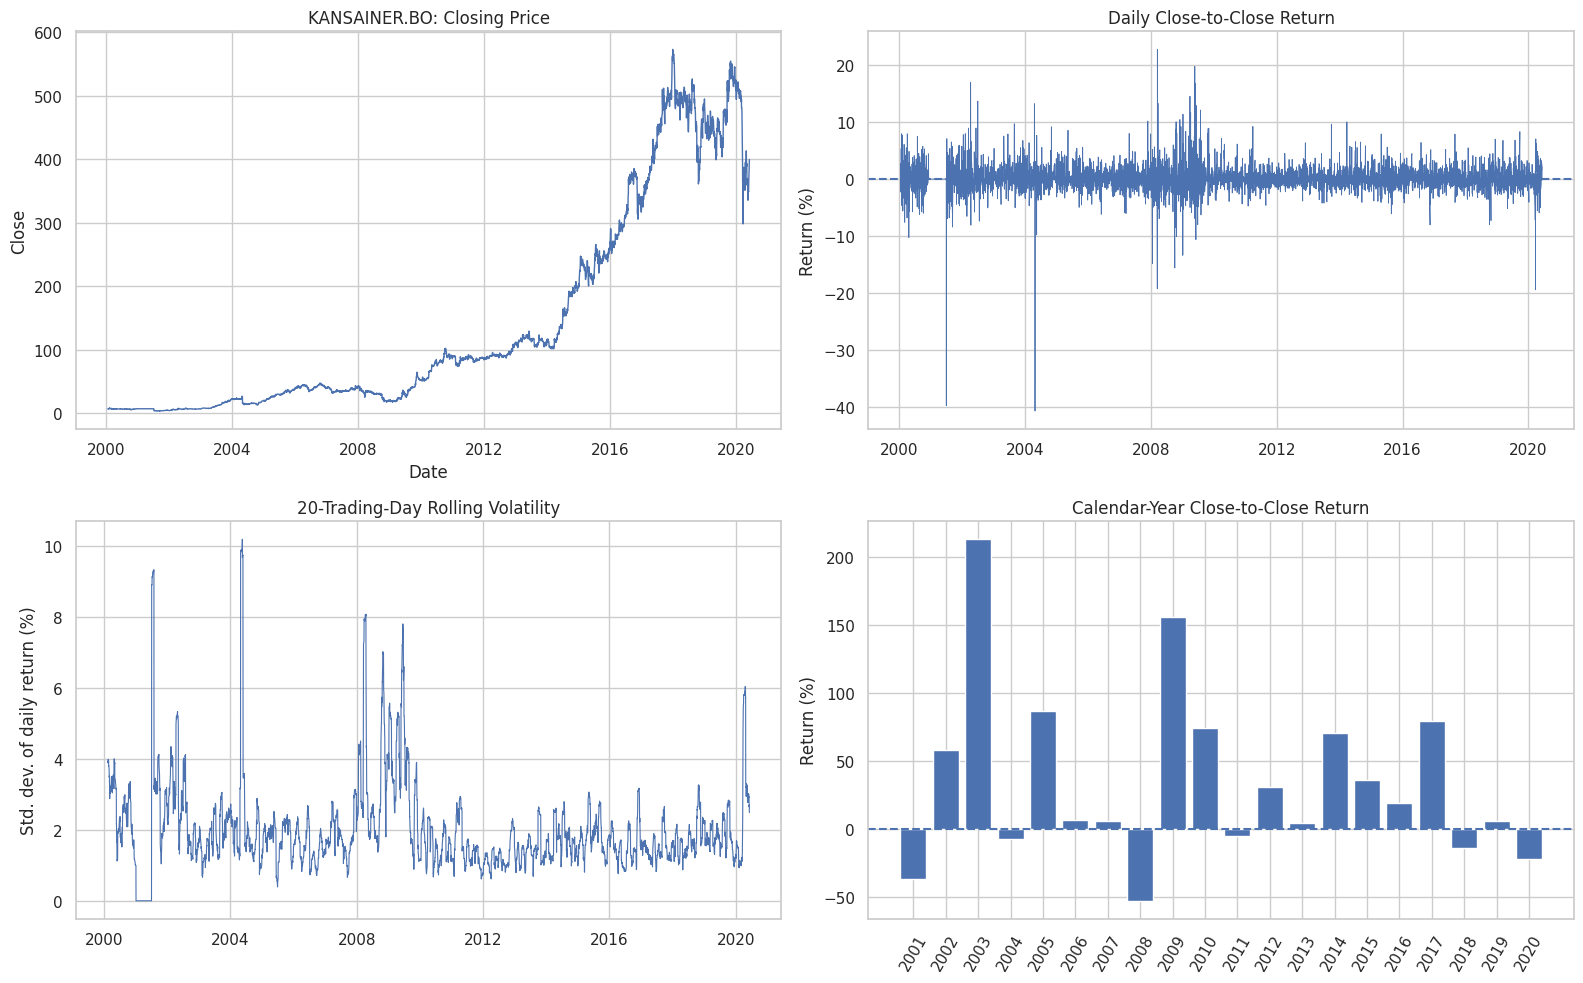

Average daily return (%): 0.10833
Daily return volatility (%): 2.35003
Best observed daily return (%): 22.809
Worst observed daily return (%): -40.783


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(stock["Date"], stock["Close"], linewidth=1)
axes[0, 0].set_title(f"{SELECTED_STOCK}: Closing Price")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Close")

stock["Daily_Return_%"] = stock["Close"].pct_change() * 100
axes[0, 1].plot(stock["Date"], stock["Daily_Return_%"], linewidth=0.6)
axes[0, 1].axhline(0, linestyle="--")
axes[0, 1].set_title("Daily Close-to-Close Return")
axes[0, 1].set_ylabel("Return (%)")

stock["Rolling_Volatility_20d"] = stock["Daily_Return_%"].rolling(20).std()
axes[1, 0].plot(stock["Date"], stock["Rolling_Volatility_20d"], linewidth=0.8)
axes[1, 0].set_title("20-Trading-Day Rolling Volatility")
axes[1, 0].set_ylabel("Std. dev. of daily return (%)")

annual = stock.set_index("Date")["Close"].resample("YE").last().pct_change() * 100
annual.index = annual.index.year
annual = annual.dropna()
axes[1, 1].bar(annual.index.astype(str), annual.values)
axes[1, 1].axhline(0, linestyle="--")
axes[1, 1].set_title("Calendar-Year Close-to-Close Return")
axes[1, 1].set_ylabel("Return (%)")
axes[1, 1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

print("Average daily return (%):", round(stock["Daily_Return_%"].mean(), 5))
print("Daily return volatility (%):", round(stock["Daily_Return_%"].std(), 5))
print("Best observed daily return (%):", round(stock["Daily_Return_%"].max(), 3))
print("Worst observed daily return (%):", round(stock["Daily_Return_%"].min(), 3))

## 8. Identify market ups and downs

For this descriptive analysis, classify each daily return as **Up** (> 0), **Down** (< 0), or **Flat** (= 0). This is an analytical label, not a prediction.

,trading_days
Market_Direction,
Down,2358
Up,2354
Flat,377


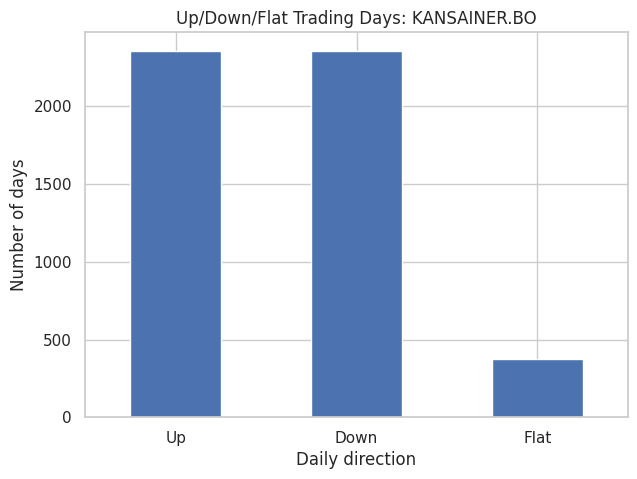

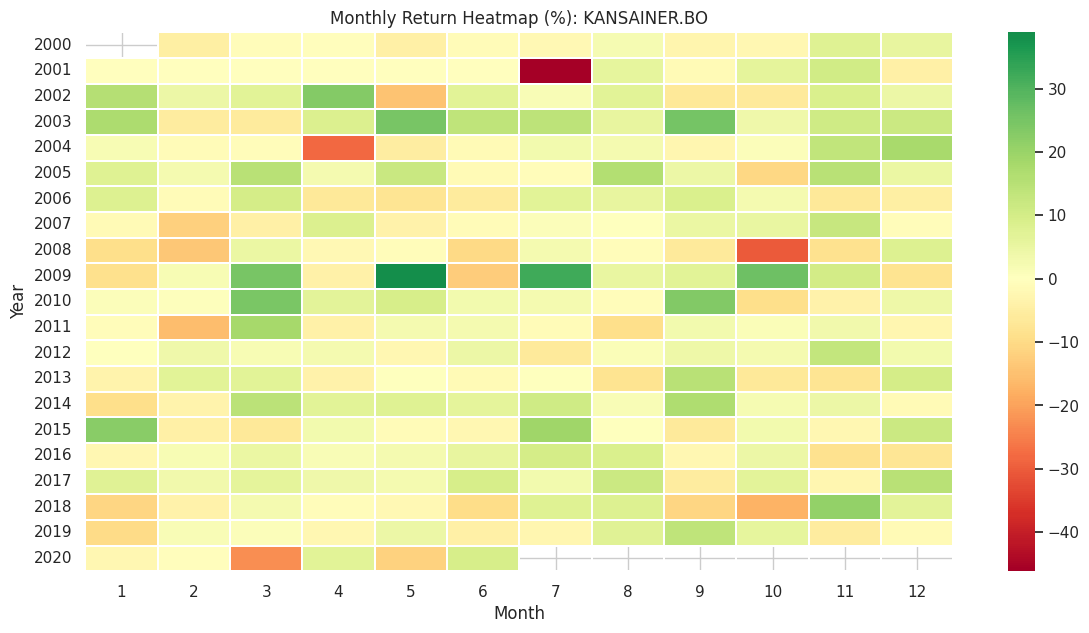

In [ ]:
stock["Market_Direction"] = np.select(
    [stock["Daily_Return_%"] > 0, stock["Daily_Return_%"] < 0],
    ["Up", "Down"],
    default="Flat"
)

direction_counts = stock["Market_Direction"].value_counts()
display(direction_counts.to_frame("trading_days"))

plt.figure(figsize=(7, 5))
direction_counts.reindex(["Up", "Down", "Flat"]).plot(kind="bar")
plt.title(f"Up/Down/Flat Trading Days: {SELECTED_STOCK}")
plt.xlabel("Daily direction")
plt.ylabel("Number of days")
plt.xticks(rotation=0)
plt.show()

monthly_return = stock.set_index("Date")["Close"].resample("ME").last().pct_change() * 100
monthly_matrix = monthly_return.to_frame("Monthly_Return")
monthly_matrix["Year"] = monthly_matrix.index.year
monthly_matrix["Month"] = monthly_matrix.index.month
heatmap_data = monthly_matrix.pivot(index="Year", columns="Month", values="Monthly_Return")

plt.figure(figsize=(14, 7))
sns.heatmap(heatmap_data, cmap="RdYlGn", center=0, linewidths=0.2)
plt.title(f"Monthly Return Heatmap (%): {SELECTED_STOCK}")
plt.xlabel("Month")
plt.ylabel("Year")
plt.show()

## 9. Feature engineering for next-day return prediction

Each row at date *t* uses information available up to date *t* to predict the return from close *t* to close *t+1*. Features include lagged returns, moving-average gaps, and rolling volatility. The target is shifted backward so the target return is the **next** session's return.

In [ ]:
base_cols = ["Date", "Close"] + [c for c in ["Open", "High", "Low", "Volume"] if c in stock.columns]
model_df = stock[base_cols].copy()
model_df["return_1d"] = model_df["Close"].pct_change() * 100
model_df["return_2d"] = model_df["Close"].pct_change(2) * 100
model_df["return_5d"] = model_df["Close"].pct_change(5) * 100
model_df["return_10d"] = model_df["Close"].pct_change(10) * 100

for window in [5, 10, 20, 50]:
    ma = model_df["Close"].rolling(window).mean()
    model_df[f"close_vs_ma_{window}"] = (model_df["Close"] / ma - 1) * 100

model_df["volatility_5d"] = model_df["return_1d"].rolling(5).std()
model_df["volatility_20d"] = model_df["return_1d"].rolling(20).std()
model_df["intraday_range_pct"] = (model_df["High"] - model_df["Low"]) / model_df["Close"] * 100 if {"High", "Low"}.issubset(model_df.columns) else np.nan
if "Open" in model_df.columns:
    model_df["open_gap_pct"] = (model_df["Open"] / model_df["Close"].shift(1) - 1) * 100
if "Volume" in model_df.columns:
    model_df["volume_change_pct"] = model_df["Volume"].pct_change().replace([np.inf, -np.inf], np.nan) * 100

# The row at t predicts the close-to-close return from t to t+1.
model_df["target_next_return"] = (model_df["Close"].shift(-1) / model_df["Close"] - 1) * 100
model_df = model_df.replace([np.inf, -np.inf], np.nan)

feature_cols = [
    c for c in model_df.columns
    if c not in ["Date", "target_next_return", "Open", "High", "Low", "Close", "Volume"]
]
# Add only engineered features, not raw price levels.
feature_cols += [c for c in ["intraday_range_pct", "open_gap_pct", "volume_change_pct"] if c in model_df.columns]
feature_cols = list(dict.fromkeys(feature_cols))

model_data = model_df.dropna(subset=["target_next_return"]).copy()
# Retain rows even if some feature is missing; imputation is fit only on training data.
model_data = model_data.sort_values("Date").reset_index(drop=True)

print("Feature columns:", feature_cols)
print("Rows before feature cleaning:", len(model_data))
display(model_data[["Date"] + feature_cols + ["target_next_return"]].tail())

Feature columns: ['return_1d', 'return_2d', 'return_5d', 'return_10d', 'close_vs_ma_5', 'close_vs_ma_10', 'close_vs_ma_20', 'close_vs_ma_50', 'volatility_5d', 'volatility_20d', 'intraday_range_pct', 'open_gap_pct', 'volume_change_pct']
Rows before feature cleaning: 5088


,Date,return_1d,return_2d,return_5d,return_10d,close_vs_ma_5,close_vs_ma_10,close_vs_ma_20,close_vs_ma_50,volatility_5d,volatility_20d,intraday_range_pct,open_gap_pct,volume_change_pct,target_next_return
5083,2020-05-29,1.486939,4.777617,1.543378,1.191627,2.775197,3.629809,0.100743,-1.895726,2.026718,2.911224,2.861841,-0.152859,9.298018,2.902918
5084,2020-06-01,2.902918,4.433022,6.369427,3.913162,4.435922,6.211576,3.539494,1.372953,1.894919,2.930372,2.009311,2.697523,-3.050330,1.556888
5085,2020-06-02,1.556888,4.505001,9.106506,11.140236,4.216738,6.711412,5.255175,3.243123,1.423284,2.655577,3.563943,3.526281,17.339626,2.227463
5086,2020-06-03,2.227463,3.819030,11.936874,16.256898,4.171119,7.449287,7.627897,5.680354,0.785638,2.698145,6.626500,2.725365,172.098913,-0.192258
5087,2020-06-04,-0.192258,2.030922,8.212901,12.188451,2.355478,6.007598,7.477314,5.499753,1.153047,2.697651,4.494671,3.306843,-52.069419,2.658278


## 10. Chronological train/test split

We use the first 80% of observations for training and the final 20% for testing. Do not shuffle time-series rows: a random split can let the model learn from later periods and then evaluate on earlier ones.

In [ ]:
split_idx = int(len(model_data) * 0.80)
train_df = model_data.iloc[:split_idx].copy()
test_df = model_data.iloc[split_idx:].copy()

X_train = train_df[feature_cols]
y_train = train_df["target_next_return"]
X_test = test_df[feature_cols]
y_test = test_df["target_next_return"]

print("Train dates:", train_df["Date"].min().date(), "to", train_df["Date"].max().date())
print("Test dates: ", test_df["Date"].min().date(), "to", test_df["Date"].max().date())
print("Training rows:", len(train_df), "| Test rows:", len(test_df))

Train dates: 2000-01-17 to 2016-04-11
Test dates:  2016-04-12 to 2020-06-04
Training rows: 4070 | Test rows: 1018


## 11. Train and compare machine learning models

- **Zero-return baseline:** predicts that the next day's return is 0%.
- **Linear Regression:** simple interpretable regression baseline.
- **Random Forest:** captures nonlinear relationships between engineered features.

Imputation and scaling are fit using the training data only. Random Forest does not require scaling, but using a pipeline keeps missing-value handling consistent.

In [ ]:
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=250,
            max_depth=10,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

predictions = {"Zero-return baseline": np.zeros(len(y_test))}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

def directional_accuracy(y_true, y_pred):
    # Exact zero predictions count as non-positive; direction is evaluated by sign.
    return np.mean(np.sign(np.asarray(y_true)) == np.sign(np.asarray(y_pred))) * 100

results = []
for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "MAE (%)": mean_absolute_error(y_test, y_pred),
        "RMSE (%)": np.sqrt(mean_squared_error(y_test, y_pred)),
        "Directional Accuracy (%)": directional_accuracy(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE (%)").reset_index(drop=True)
display(results_df.style.format({
    "MAE (%)": "{:.4f}",
    "RMSE (%)": "{:.4f}",
    "Directional Accuracy (%)": "{:.2f}"
}))

# Pick the best *trained* model (the zero-return baseline has no .predict(), so it is excluded here).
baseline_name = "Zero-return baseline"
trained_results = results_df[results_df["Model"] != baseline_name].reset_index(drop=True)
best_model_name = trained_results.iloc[0]["Model"]

baseline_rmse = results_df.loc[results_df["Model"] == baseline_name, "RMSE (%)"].iloc[0]
best_rmse = trained_results.iloc[0]["RMSE (%)"]
beats_baseline = best_rmse < baseline_rmse

print(f"\nBest trained model by test RMSE: {best_model_name}")
print(f"Test RMSE: {best_rmse:.4f}% vs zero-return baseline {baseline_rmse:.4f}% -> "
      f"{'beats' if beats_baseline else 'does NOT beat'} the baseline")

# The zero baseline never predicts a direction, so its directional accuracy is not meaningful.
# A fairer reference is "always predict Up":
always_up_acc = (np.asarray(y_test) > 0).mean() * 100
print(f"Reference: always predicting 'Up' would be right {always_up_acc:.2f}% of the time on the test set.")


,Model,MAE (%),RMSE (%),Directional Accuracy (%)
0,Zero-return baseline,1.3280,1.9291,0.39
1,Random Forest,1.3483,1.9659,46.86
2,Linear Regression,1.3545,1.9757,48.13



Best trained model by test RMSE: Random Forest
Test RMSE: 1.9659% vs zero-return baseline 1.9291% -> does NOT beat the baseline
Reference: always predicting 'Up' would be right 48.23% of the time on the test set.


## 12. Plot actual versus predicted returns

Daily returns are noisy. Focus on whether the model improves on the zero-return baseline and whether its directional accuracy is meaningfully better than chance—not just whether a chart looks smooth.

Best model by test RMSE: Zero-return baseline


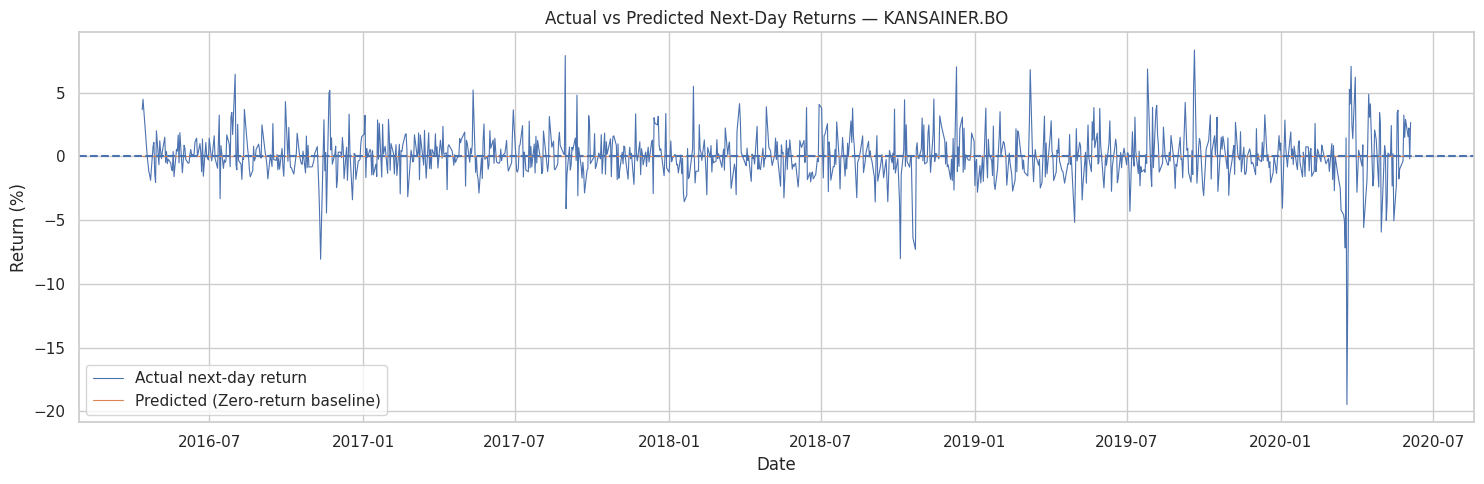

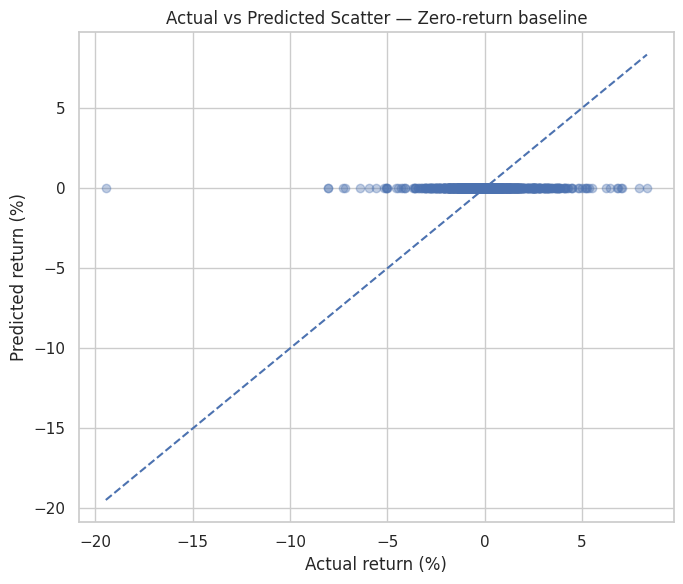

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
print("Best model by test RMSE:", best_model_name)

plt.figure(figsize=(15, 5))
plt.plot(test_df["Date"], y_test.values, label="Actual next-day return", linewidth=0.8)
plt.plot(test_df["Date"], predictions[best_model_name], label=f"Predicted ({best_model_name})", linewidth=0.8)
plt.axhline(0, linestyle="--")
plt.title(f"Actual vs Predicted Next-Day Returns — {SELECTED_STOCK}")
plt.xlabel("Date")
plt.ylabel("Return (%)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions[best_model_name], alpha=0.35)
lims = [
    min(np.nanmin(y_test), np.nanmin(predictions[best_model_name])),
    max(np.nanmax(y_test), np.nanmax(predictions[best_model_name]))
]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Actual return (%)")
plt.ylabel("Predicted return (%)")
plt.title(f"Actual vs Predicted Scatter — {best_model_name}")
plt.tight_layout()
plt.show()

## 13. Feature importance (Random Forest)

Feature importance is a descriptive model diagnostic, not proof that a feature causes stock returns. The model can still overfit historical patterns.

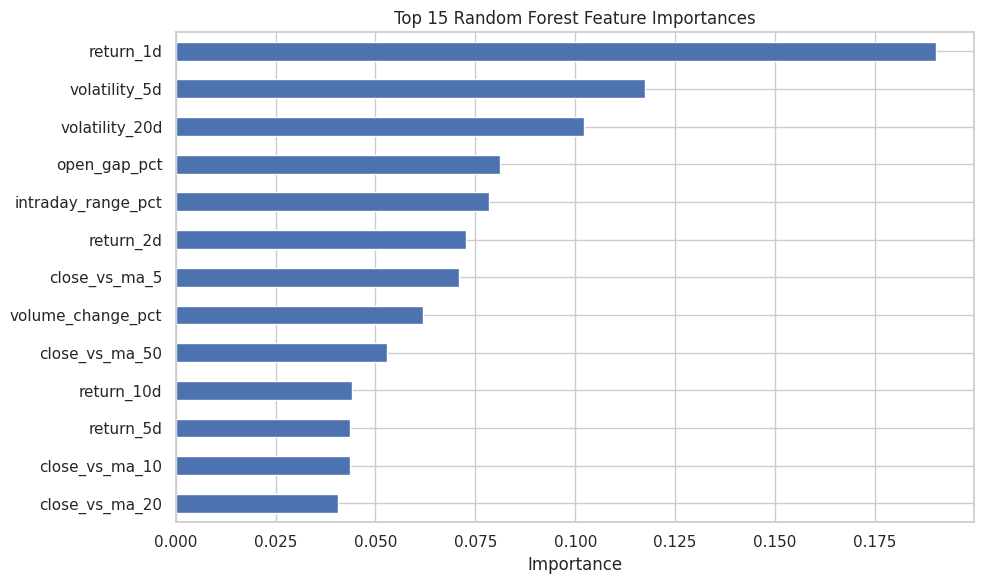

,importance
return_1d,0.190288
volatility_5d,0.117520
volatility_20d,0.102278
open_gap_pct,0.081176
intraday_range_pct,0.078377
return_2d,0.072565
close_vs_ma_5,0.071016
volume_change_pct,0.061981
close_vs_ma_50,0.052815
return_10d,0.044037


In [ ]:
rf = models["Random Forest"].named_steps["model"]
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importances.head(15).to_frame("importance"))

## 14. Predict the next available trading session's return

This uses the most recent row's engineered features and the best model selected by test RMSE. The prediction is an estimate of percentage return, **not a guaranteed price or trading signal**. The data ends in 2020 if that is the range in your files, so this forecast refers to the next session after the last available historical observation—not today's market.

In [ ]:
best_model = models[best_model_name]


# Build the most recent feature row from the same feature engineering pipeline.
latest_feature_row = model_df.sort_values("Date").iloc[[-1]][feature_cols]
if latest_feature_row.isna().all(axis=1).iloc[0]:
    raise ValueError("Latest row has no usable engineered features; inspect the data.")

predicted_return_pct = float(best_model.predict(latest_feature_row)[0])
last_date = model_df["Date"].max()
last_close = float(model_df.loc[model_df["Date"] == last_date, "Close"].iloc[-1])
estimated_next_close = last_close * (1 + predicted_return_pct / 100)

print("Selected series:", SELECTED_STOCK)
print("Last historical date:", last_date.date())
print(f"Last close: {last_close:.2f}")
print(f"Estimated next-session return: {predicted_return_pct:.4f}%")
print(f"Illustrative implied close: {estimated_next_close:.2f}")
print("Reminder: this is an educational model estimate, not financial advice.")

Selected series: KANSAINER.BO
Last historical date: 2020-06-05
Last close: 399.70
Estimated next-session return: -0.4149%
Illustrative implied close: 398.04
Reminder: this is an educational model estimate, not financial advice.


In [ ]:
!pip -q install streamlit

# Save the cleaned data prepared by the notebook for the Streamlit app.
all_stocks.to_csv('/content/stock_project_data_for_streamlit.csv', index=False)

app_code = 'import streamlit as st\nimport pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom sklearn.ensemble import RandomForestRegressor\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler\n\nst.set_page_config(page_title="Indian Stock Return Predictor", page_icon="📈", layout="wide")\nst.title("📈 Indian Stock Market Return Prediction")\nst.caption("Explore historical prices and estimate the next available session\'s return. Educational use only — not investment advice.")\n\n@st.cache_data\ndef load_data():\n    return pd.read_csv("/content/stock_project_data_for_streamlit.csv", parse_dates=["Date"])\n\nall_stocks = load_data()\noptions = sorted(all_stocks["Stock"].dropna().unique())\nif not options:\n    st.error("No stock series found. Run the notebook\'s data-loading and preprocessing cells first.")\n    st.stop()\n\nwith st.sidebar:\n    st.header("Controls")\n    selected = st.selectbox("Choose stock/index", options)\n    model_choice = st.selectbox("Prediction model", ["Best by test RMSE", "Linear Regression", "Random Forest"])\n    train_pct = st.slider("Training data (%)", 60, 90, 80, 5)\n    st.info("The forecast is for the session after the last date in your uploaded data, not necessarily today\'s market.")\n\nstock = all_stocks[all_stocks["Stock"] == selected].copy()\nstock = stock.sort_values("Date").drop_duplicates("Date").dropna(subset=["Date", "Close"]).reset_index(drop=True)\nif len(stock) < 100:\n    st.warning("This series has fewer than 100 valid rows; metrics may be unreliable.")\nif len(stock) < 30:\n    st.error("Not enough observations to build the model.")\n    st.stop()\n\nstock["return_1d"] = stock["Close"].pct_change() * 100\nstock["return_2d"] = stock["Close"].pct_change(2) * 100\nstock["return_5d"] = stock["Close"].pct_change(5) * 100\nstock["return_10d"] = stock["Close"].pct_change(10) * 100\nfor window in [5, 10, 20, 50]:\n    stock[f"close_vs_ma_{window}"] = (stock["Close"] / stock["Close"].rolling(window).mean() - 1) * 100\nstock["volatility_5d"] = stock["return_1d"].rolling(5).std()\nstock["volatility_20d"] = stock["return_1d"].rolling(20).std()\nif {"High", "Low"}.issubset(stock.columns):\n    stock["intraday_range_pct"] = (stock["High"] - stock["Low"]) / stock["Close"] * 100\nelse:\n    stock["intraday_range_pct"] = np.nan\nif "Open" in stock.columns:\n    stock["open_gap_pct"] = (stock["Open"] / stock["Close"].shift(1) - 1) * 100\nif "Volume" in stock.columns:\n    stock["volume_change_pct"] = stock["Volume"].pct_change().replace([np.inf, -np.inf], np.nan) * 100\n\nfeature_cols = [c for c in stock.columns if c.startswith(("return_", "close_vs_ma_", "volatility_", "intraday_range_pct", "open_gap_pct", "volume_change_pct"))]\ndata = stock[["Date", "Close"] + feature_cols].copy()\ndata["target_next_return"] = data["Close"].pct_change().shift(-1) * 100\ndata = data.replace([np.inf, -np.inf], np.nan).dropna(subset=["target_next_return"]).reset_index(drop=True)\nif len(data) < 30:\n    st.error("Not enough usable rows after feature engineering.")\n    st.stop()\n\nsplit = int(len(data) * train_pct / 100)\ntrain, test = data.iloc[:split], data.iloc[split:]\nX_train, y_train = train[feature_cols], train["target_next_return"]\nX_test, y_test = test[feature_cols], test["target_next_return"]\nmodels = {\n    "Linear Regression": Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", LinearRegression())]),\n    "Random Forest": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", RandomForestRegressor(n_estimators=250, max_depth=10, min_samples_leaf=5, random_state=42, n_jobs=-1))])\n}\npreds = {"Zero-return baseline": np.zeros(len(y_test))}\nfor name, model in models.items():\n    model.fit(X_train, y_train)\n    preds[name] = model.predict(X_test)\nmetrics = []\nfor name, pred in preds.items():\n    metrics.append({"Model": name, "MAE (%)": mean_absolute_error(y_test, pred), "RMSE (%)": np.sqrt(mean_squared_error(y_test, pred)), "Directional accuracy (%)": np.mean(np.sign(y_test) == np.sign(pred)) * 100})\nmetrics_df = pd.DataFrame(metrics).sort_values("RMSE (%)")\nbest = metrics_df.iloc[0]["Model"]\nchosen = best if model_choice == "Best by test RMSE" else model_choice\n\nlast_row = stock.iloc[[-1]][feature_cols].replace([np.inf, -np.inf], np.nan)\nif chosen == "Zero-return baseline":\n    forecast = 0.0\nelse:\n    # Refit the selected model on all labeled rows for the final next-session estimate.\n    final_model = models[chosen]\n    final_model.fit(data[feature_cols], data["target_next_return"])\n    forecast = float(final_model.predict(last_row)[0])\nlast_date = stock["Date"].max()\nlast_close = float(stock.loc[stock["Date"] == last_date, "Close"].iloc[-1])\nimplied_close = last_close * (1 + forecast / 100)\n\na, b, c, d = st.columns(4)\na.metric("Last close", f"{last_close:,.2f}")\nb.metric("Estimated next return", f"{forecast:+.3f}%")\nc.metric("Illustrative implied close", f"{implied_close:,.2f}")\nd.metric("Last data date", last_date.strftime("%d %b %Y"))\n\nst.subheader("Closing-price history")\nst.line_chart(stock.set_index("Date")["Close"])\nleft, right = st.columns(2)\nwith left:\n    st.subheader("Daily returns")\n    st.line_chart(stock.set_index("Date")["return_1d"].dropna())\nwith right:\n    st.subheader("Test-set model comparison")\n    st.dataframe(metrics_df, use_container_width=True, hide_index=True)\n\nst.subheader("Actual vs predicted next-session returns (test period)")\nfig, ax = plt.subplots(figsize=(12, 4))\nax.plot(test["Date"], y_test.values, label="Actual", linewidth=1)\nax.plot(test["Date"], preds[chosen] if chosen in preds else preds[best], label=f"Predicted: {chosen}", linewidth=1)\nax.axhline(0, linestyle="--", linewidth=0.8)\nax.set_ylabel("Return (%)")\nax.legend()\nax.grid(alpha=0.2)\nst.pyplot(fig)\nplt.close(fig)\n\nst.subheader("Latest observations")\nst.dataframe(stock[["Date", "Close"]].tail(10).sort_values("Date", ascending=False), use_container_width=True, hide_index=True)\ncsv = stock.to_csv(index=False).encode("utf-8")\nst.download_button("Download selected stock data (CSV)", csv, file_name=f"{selected.replace(\' \', \'_\')}_history.csv", mime="text/csv")\nst.warning("Historical model estimates are not reliable guarantees of future returns. This app is for learning, not trading advice.")\n'
with open('/content/stock_app.py', 'w', encoding='utf-8') as f:
    f.write(app_code)

# Start Streamlit in the background, then create a public temporary tunnel.
import subprocess, time, os
log_file = open('/content/streamlit.log', 'w')
streamlit_proc = subprocess.Popen(['streamlit', 'run', '/content/stock_app.py', '--server.port', '8501', '--server.address', '0.0.0.0', '--server.headless', 'true'], stdout=log_file, stderr=subprocess.STDOUT)
time.sleep(5)
print('Streamlit process started. The next cell creates the access URL.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 57.6 MB/s eta 0:00:00
Streamlit process started. The next cell creates the access URL.


In [ ]:
!npx --yes localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸your url is: https://thin-pigs-remain.loca.lt
^C


## 15. Conclusion and report points

1. **Objective:** Explore historical Indian stock market behavior and predict next-session stock returns.
2. **Preprocessing:** Extracted zipped Excel/CSV files, standardized column names, parsed dates, removed invalid prices, and restricted observations to 2000–2020.
3. **EDA:** Analyzed closing-price trends, daily returns, rolling volatility, yearly performance, and up/down days.
4. **Feature engineering:** Used lagged returns, moving-average gaps, volatility, intraday range, opening gap, and volume change where available.
5. **Models:** Compared a zero-return baseline, Linear Regression, and Random Forest.
6. **Evaluation:** Used chronological 80/20 split and reported MAE, RMSE, and directional accuracy.
7. **Limitations:** Stock returns are noisy; the archive may contain only selected stocks and may have survivorship bias. Corporate actions, transaction costs, regime changes, and macroeconomic/news factors may not be fully represented. A lower RMSE does not automatically imply a profitable strategy.
8. **Future scope:** Add a walk-forward validation, compare Gradient Boosting models, include market-wide index features, and backtest a clearly defined strategy after accounting for transaction costs.

### Suggested references
- Dataset: [Kaggle — Stock Data](https://www.kaggle.com/datasets/sagara9595/stock-data)
- Python: Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn documentation.